In [ ]:
# what are the category percentages of ladd and pia flights??

# what is the percentile distrubtion of altitudes
# what is the percentage distrubtion of calcualted speeds. 
# We could do this on already labelled flights with the basic algorithm. 

In [6]:
from datetime import date
import polars as pl
dates = [
    date(2026, 3, 1),
    date(2026, 6, 1),
]
from data_engineering.adsb.read_adsb import read_adsb
from data_engineering.flights.flight_type import get_flights

dfs = [get_flights(d) for d in dates]

df = pl.concat(dfs)

In [ ]:
df_adsb = pl.concat([read_adsb(d, pia_or_american_ladd_only=True) for d in dates])

time,icao,registration,callsign,lat,lon,baro_altitude_ft,on_ground,ground_speed_kt,track_deg,aircraft_type,aircraft_description,owner,category,pia,ladd,military,interesting
datetime[ms],str,str,str,f64,f64,i32,bool,f32,f32,str,str,str,str,bool,bool,bool,bool
2026-03-01 16:43:56.720,"""a0001a""","""N1AZ""","""CXF1""",33.629313,-111.908183,null,true,5.2,84.400002,"""FA7X""","""DASSAULT Falcon 7X""","""WILMINGTON TRUST CO TRUSTEE""","""A2""",false,true,false,false
2026-03-01 16:43:58.090,"""a0001a""","""N1AZ""",null,33.629311,-111.90814,null,true,5.2,87.199997,"""FA7X""","""DASSAULT Falcon 7X""","""WILMINGTON TRUST CO TRUSTEE""",null,false,true,false,false
2026-03-01 16:44:04.450,"""a0001a""","""N1AZ""",null,33.629313,-111.907969,null,true,5.2,90.0,"""FA7X""","""DASSAULT Falcon 7X""","""WILMINGTON TRUST CO TRUSTEE""",null,false,true,false,false
2026-03-01 16:44:17.090,"""a0001a""","""N1AZ""",null,33.629313,-111.907611,null,true,4.8,90.0,"""FA7X""","""DASSAULT Falcon 7X""","""WILMINGTON TRUST CO TRUSTEE""",null,false,true,false,false
2026-03-01 16:44:27.070,"""a0001a""","""N1AZ""","""CXF1""",33.629311,-111.907299,null,true,6.2,90.0,"""FA7X""","""DASSAULT Falcon 7X""","""WILMINGTON TRUST CO TRUSTEE""","""A2""",false,true,false,false
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2026-06-01 15:18:25.900,"""adf658""","""N999ZG""",null,39.241395,-86.844666,4800,false,257.799988,96.699997,"""B350""","""BEECHCRAFT Super King Air 350""","""CFC LLC""",null,false,true,false,false
2026-06-01 15:18:27.410,"""adf658""","""N999ZG""",null,39.241209,-86.842285,4750,false,255.699997,96.5,"""B350""","""BEECHCRAFT Super King Air 350""","""CFC LLC""",null,false,true,false,false
2026-06-01 15:18:37.110,"""adf658""","""N999ZG""",null,39.239859,-86.827942,4475,false,252.800003,96.800003,"""B350""","""BEECHCRAFT Super King Air 350""","""CFC LLC""","""A1""",false,true,false,false


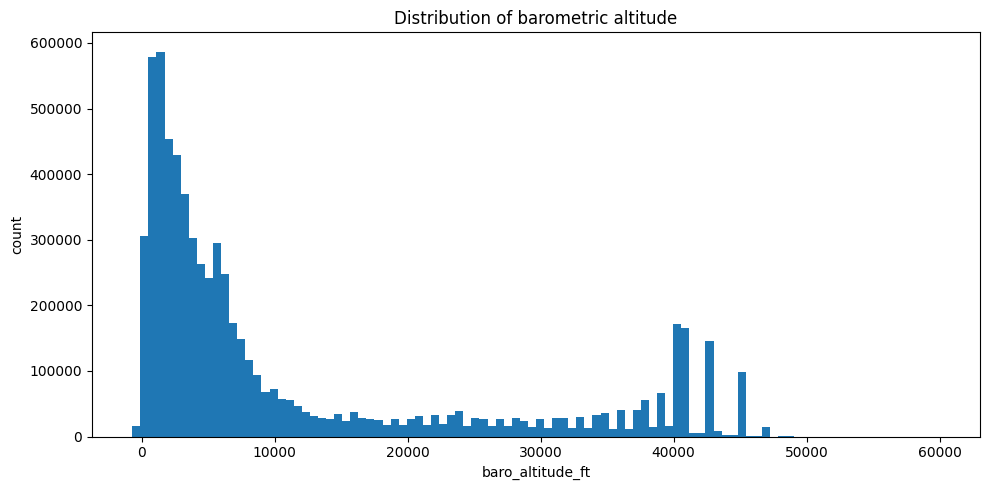

In [12]:
import matplotlib.pyplot as plt

altitudes = (
    df_adsb
    .get_column("baro_altitude_ft")
    .drop_nulls()
    .to_numpy()
)

plt.figure(figsize=(10, 5))
plt.hist(altitudes, bins=100)
plt.xlabel("baro_altitude_ft")
plt.ylabel("count")
plt.title("Distribution of barometric altitude")
plt.tight_layout()
plt.show()

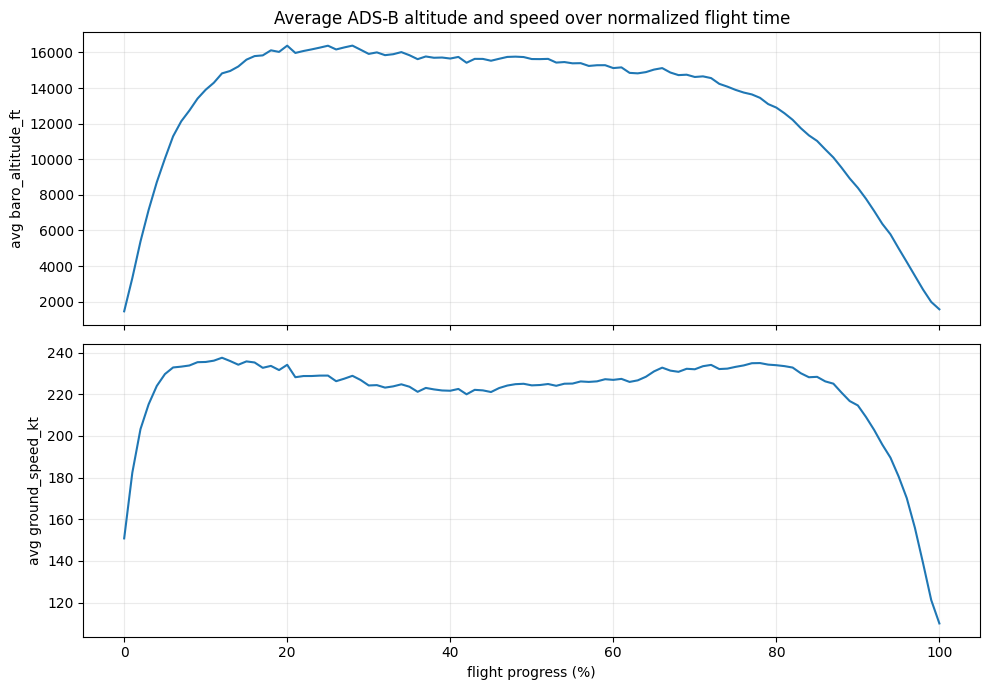

flight_progress_pct,avg_baro_altitude_ft,avg_ground_speed_kt,adsb_row_count,flight_count
i64,f64,f32,u32,u32
0,1456.095954,150.828049,126473,8813
1,3323.388961,182.397629,195898,8545
2,5380.285801,203.283432,140230,8560
3,7151.411985,215.215988,110596,8585
4,8707.798944,224.020172,95827,8654
…,…,…,…,…
96,4228.022423,170.169876,112725,9040
97,3450.44249,155.90303,133739,8995
98,2675.950837,138.917313,168254,8875


In [14]:
import warnings

import polars as pl
import matplotlib.pyplot as plt

flight_windows = (
    df
    .with_row_index("flight_idx")
    .filter(pl.col("landing_time") > pl.col("takeoff_time"))
    .select(["flight_idx", "icao", "takeoff_time", "landing_time"])
    .sort(["icao", "takeoff_time"])
)

with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore",
        message="Sortedness of columns cannot be checked when 'by' groups provided",
    )
    adsb_flight_points = (
        df_adsb
        .select(["time", "icao", "baro_altitude_ft", "ground_speed_kt"])
        .filter(
            pl.col("time").is_not_null()
            & pl.col("icao").is_not_null()
            & (
                pl.col("baro_altitude_ft").is_not_null()
                | pl.col("ground_speed_kt").is_not_null()
            )
        )
        .sort(["icao", "time"])
        .join_asof(
            flight_windows,
            left_on="time",
            right_on="takeoff_time",
            by="icao",
            strategy="backward",
        )
        .filter(
            pl.col("landing_time").is_not_null()
            & (pl.col("time") <= pl.col("landing_time"))
        )
        .with_columns(
            (
                (pl.col("time") - pl.col("takeoff_time")).dt.total_milliseconds()
                / (pl.col("landing_time") - pl.col("takeoff_time")).dt.total_milliseconds()
            ).alias("flight_progress")
        )
        .filter(pl.col("flight_progress").is_between(0, 1))
        .with_columns(
            (pl.col("flight_progress") * 100)
            .round(0)
            .cast(pl.Int64)
            .alias("flight_progress_pct")
        )
    )

flight_profile = (
    adsb_flight_points
    .group_by("flight_progress_pct")
    .agg(
        pl.col("baro_altitude_ft").mean().alias("avg_baro_altitude_ft"),
        pl.col("ground_speed_kt").mean().alias("avg_ground_speed_kt"),
        pl.len().alias("adsb_row_count"),
        pl.col("flight_idx").n_unique().alias("flight_count"),
    )
    .sort("flight_progress_pct")
)

profile_pdf = flight_profile.to_pandas()

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

axes[0].plot(
    profile_pdf["flight_progress_pct"],
    profile_pdf["avg_baro_altitude_ft"],
)
axes[0].set_ylabel("avg baro_altitude_ft")
axes[0].set_title("Average ADS-B altitude and speed over normalized flight time")
axes[0].grid(alpha=0.25)

axes[1].plot(
    profile_pdf["flight_progress_pct"],
    profile_pdf["avg_ground_speed_kt"],
)
axes[1].set_xlabel("flight progress (%)")
axes[1].set_ylabel("avg ground_speed_kt")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

flight_profile

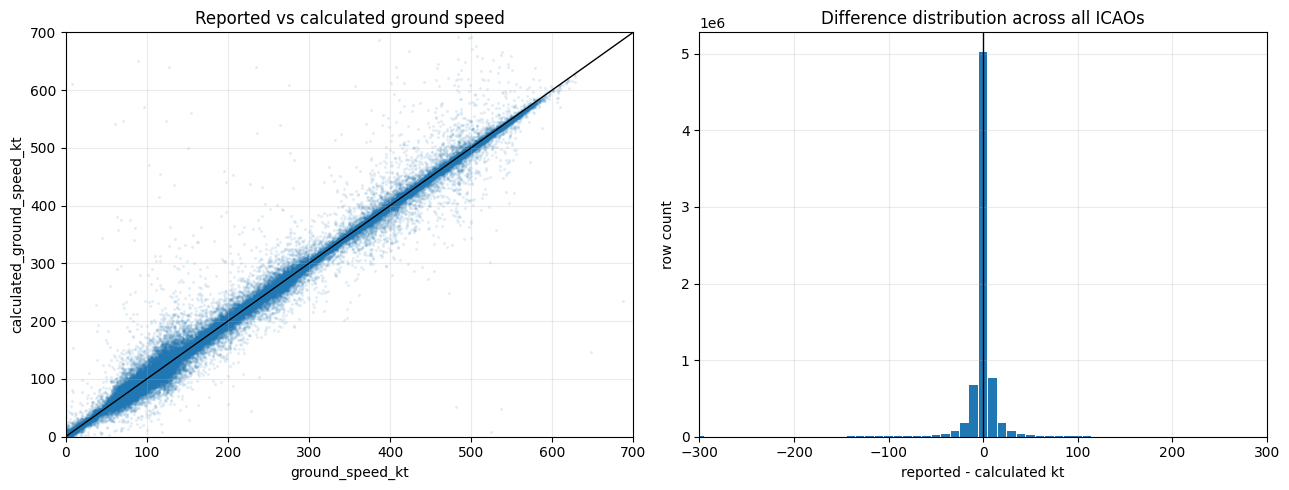

row_count,icao_count,reported_calculated_corr,mean_diff_kt,median_diff_kt,p10_diff_kt,p90_diff_kt,median_abs_diff_kt,p95_abs_diff_kt
u32,u32,f64,f64,f64,f64,f64,f64,f64
7162327,5151,0.3606,-0.98123,0.223602,-7.735404,7.684512,2.508205,24.107659


icao,row_count,mean_diff_kt,median_diff_kt,median_abs_diff_kt,p95_abs_diff_kt,reported_calculated_corr
str,u32,f64,f64,f64,f64,f64
"""a296f2""",365,-4.814531,41.706981,47.257707,223.881218,0.070665
"""aac32a""",528,-54.612318,-5.930863,41.383777,257.185924,-0.077289
"""a7c363""",104,-11.864707,2.199994,35.543981,219.718788,0.040574
"""a443d3""",1597,-6.899612,0.335477,32.502273,168.937654,0.622366
"""a061d9""",1212,-69.043667,-6.829987,31.761332,290.536689,0.077126
…,…,…,…,…,…,…
"""add65a""",442,-19.392654,-1.585143,13.196766,108.959438,0.213108
"""a46a28""",2529,-0.265338,1.053836,13.101434,97.660678,0.925555
"""a0b1bf""",2080,-0.789812,-0.095884,12.808754,55.630176,0.673993


In [17]:
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import display

max_speed_gap_seconds = 120
plot_sample_rows = 100_000
plot_speed_limit_kt = 700
diff_clip_kt = 300
diff_bin_kt = 10
min_icao_rows = 100

lat_1 = pl.col("prev_lat").radians()
lat_2 = pl.col("lat").radians()
delta_lat = (pl.col("lat") - pl.col("prev_lat")).radians()
delta_lon = (pl.col("lon") - pl.col("prev_lon")).radians()
haversine_a = (
    (delta_lat / 2).sin() ** 2
    + lat_1.cos() * lat_2.cos() * (delta_lon / 2).sin() ** 2
)
distance_km = 6371.0 * 2 * pl.arctan2(
    haversine_a.sqrt(),
    (pl.lit(1.0) - haversine_a).sqrt(),
)

speed_comparison = (
    df_adsb
    .select(["time", "icao", "lat", "lon", "ground_speed_kt"])
    .filter(
        pl.col("time").is_not_null()
        & pl.col("icao").is_not_null()
        & pl.col("lat").is_not_null()
        & pl.col("lon").is_not_null()
        & pl.col("ground_speed_kt").is_not_null()
    )
    .sort(["icao", "time"])
    .with_columns(
        pl.col("time").shift(1).over("icao").alias("prev_time"),
        pl.col("lat").shift(1).over("icao").alias("prev_lat"),
        pl.col("lon").shift(1).over("icao").alias("prev_lon"),
    )
    .with_columns(
        ((pl.col("time") - pl.col("prev_time")).dt.total_milliseconds() / 1000)
        .alias("time_gap_seconds"),
        distance_km.alias("distance_km"),
    )
    .filter(
        (pl.col("time_gap_seconds") > 0)
        & (pl.col("time_gap_seconds") <= max_speed_gap_seconds)
    )
    .with_columns(
        (pl.col("distance_km") * 1943.844492 / pl.col("time_gap_seconds"))
        .alias("calculated_ground_speed_kt")
    )
    .with_columns(
        (pl.col("ground_speed_kt") - pl.col("calculated_ground_speed_kt"))
        .alias("ground_speed_diff_kt")
    )
    .with_columns(
        pl.col("ground_speed_diff_kt").abs().alias("abs_ground_speed_diff_kt")
    )
)

speed_summary = speed_comparison.select(
    pl.len().alias("row_count"),
    pl.col("icao").n_unique().alias("icao_count"),
    pl.corr("ground_speed_kt", "calculated_ground_speed_kt").alias("reported_calculated_corr"),
    pl.col("ground_speed_diff_kt").mean().alias("mean_diff_kt"),
    pl.col("ground_speed_diff_kt").median().alias("median_diff_kt"),
    pl.col("ground_speed_diff_kt").quantile(0.10).alias("p10_diff_kt"),
    pl.col("ground_speed_diff_kt").quantile(0.90).alias("p90_diff_kt"),
    pl.col("abs_ground_speed_diff_kt").median().alias("median_abs_diff_kt"),
    pl.col("abs_ground_speed_diff_kt").quantile(0.95).alias("p95_abs_diff_kt"),
)

speed_by_icao = (
    speed_comparison
    .group_by("icao")
    .agg(
        pl.len().alias("row_count"),
        pl.col("ground_speed_diff_kt").mean().alias("mean_diff_kt"),
        pl.col("ground_speed_diff_kt").median().alias("median_diff_kt"),
        pl.col("abs_ground_speed_diff_kt").median().alias("median_abs_diff_kt"),
        pl.col("abs_ground_speed_diff_kt").quantile(0.95).alias("p95_abs_diff_kt"),
        pl.corr("ground_speed_kt", "calculated_ground_speed_kt").alias("reported_calculated_corr"),
    )
    .filter(pl.col("row_count") >= min_icao_rows)
    .sort("median_abs_diff_kt", descending=True)
)

speed_plot_candidates = speed_comparison.filter(
    pl.col("ground_speed_kt").is_between(0, plot_speed_limit_kt)
    & pl.col("calculated_ground_speed_kt").is_between(0, plot_speed_limit_kt)
)
speed_plot_sample = speed_plot_candidates.sample(
    n=min(plot_sample_rows, speed_plot_candidates.height),
    seed=0,
)

diff_hist = (
    speed_comparison
    .with_columns(
        (
            (pl.col("ground_speed_diff_kt").clip(-diff_clip_kt, diff_clip_kt) / diff_bin_kt)
            .round(0)
            * diff_bin_kt
        ).alias("diff_bin_kt")
    )
    .group_by("diff_bin_kt")
    .len()
    .sort("diff_bin_kt")
)

sample_pdf = speed_plot_sample.to_pandas()
hist_pdf = diff_hist.to_pandas()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(
    sample_pdf["ground_speed_kt"],
    sample_pdf["calculated_ground_speed_kt"],
    s=2,
    alpha=0.08,
)
axes[0].plot([0, plot_speed_limit_kt], [0, plot_speed_limit_kt], color="black", linewidth=1)
axes[0].set_xlim(0, plot_speed_limit_kt)
axes[0].set_ylim(0, plot_speed_limit_kt)
axes[0].set_xlabel("ground_speed_kt")
axes[0].set_ylabel("calculated_ground_speed_kt")
axes[0].set_title("Reported vs calculated ground speed")
axes[0].grid(alpha=0.25)

axes[1].bar(
    hist_pdf["diff_bin_kt"],
    hist_pdf["len"],
    width=diff_bin_kt * 0.9,
)
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_xlim(-diff_clip_kt, diff_clip_kt)
axes[1].set_xlabel("reported - calculated kt")
axes[1].set_ylabel("row count")
axes[1].set_title("Difference distribution across all ICAOs")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

display(speed_summary)
speed_by_icao.head(50)

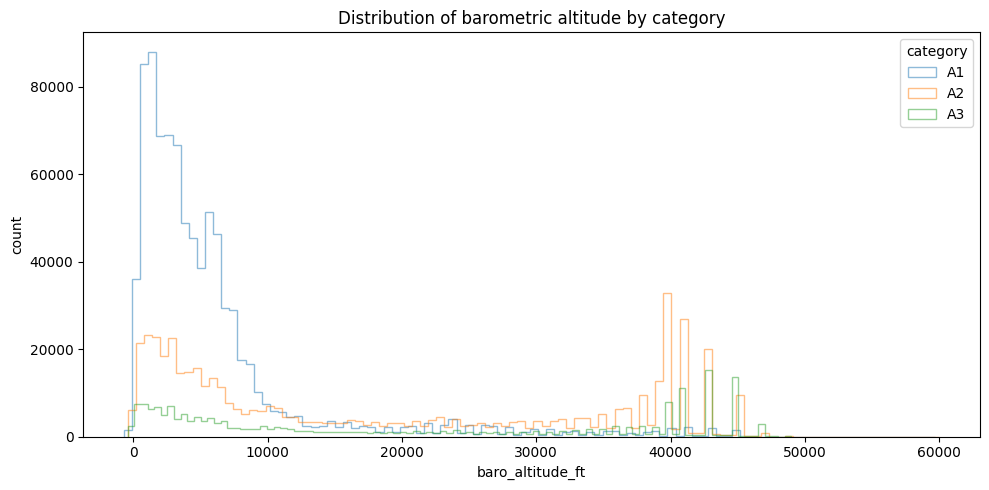

In [13]:
import polars as pl
import matplotlib.pyplot as plt

df_plot = (
    df_adsb
    .filter(
        pl.col("category").is_in(["A1", "A2", "A3"])
        & pl.col("baro_altitude_ft").is_not_null()
    )
    .select(["category", "baro_altitude_ft"])
)

plt.figure(figsize=(10, 5))

for category in ["A1", "A2", "A3"]:
    altitudes = (
        df_plot
        .filter(pl.col("category") == category)
        .get_column("baro_altitude_ft")
        .to_numpy()
    )

    plt.hist(
        altitudes,
        bins=100,
        alpha=0.5,
        label=category,
        histtype="step",
    )

plt.xlabel("baro_altitude_ft")
plt.ylabel("count")
plt.title("Distribution of barometric altitude by category")
plt.legend(title="category")
plt.tight_layout()
plt.show()

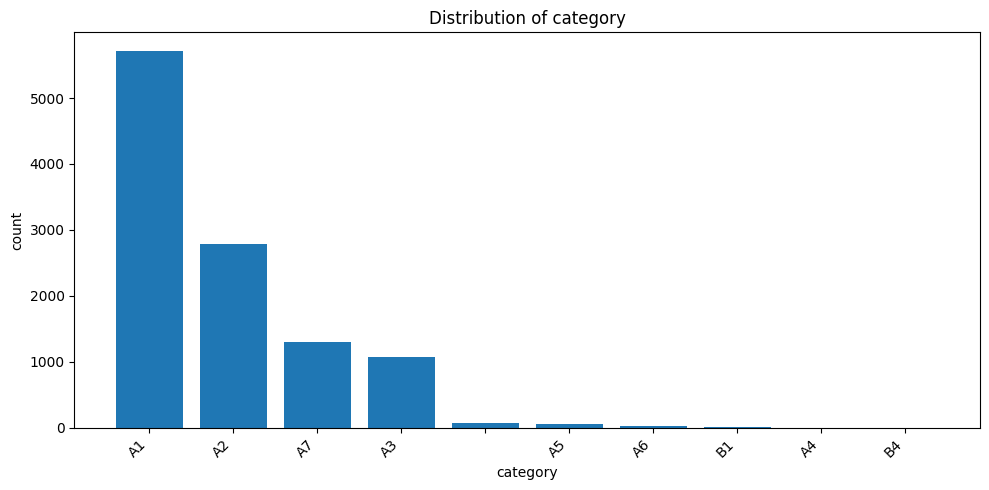

In [9]:
import polars as pl
import matplotlib.pyplot as plt

counts = (
    df.get_column("category")
    .value_counts()
    .sort("count", descending=True)
)

pdf = counts.to_pandas()

plt.figure(figsize=(10, 5))
plt.bar(pdf["category"].astype(str), pdf["count"])
plt.xlabel("category")
plt.ylabel("count")
plt.title("Distribution of category")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

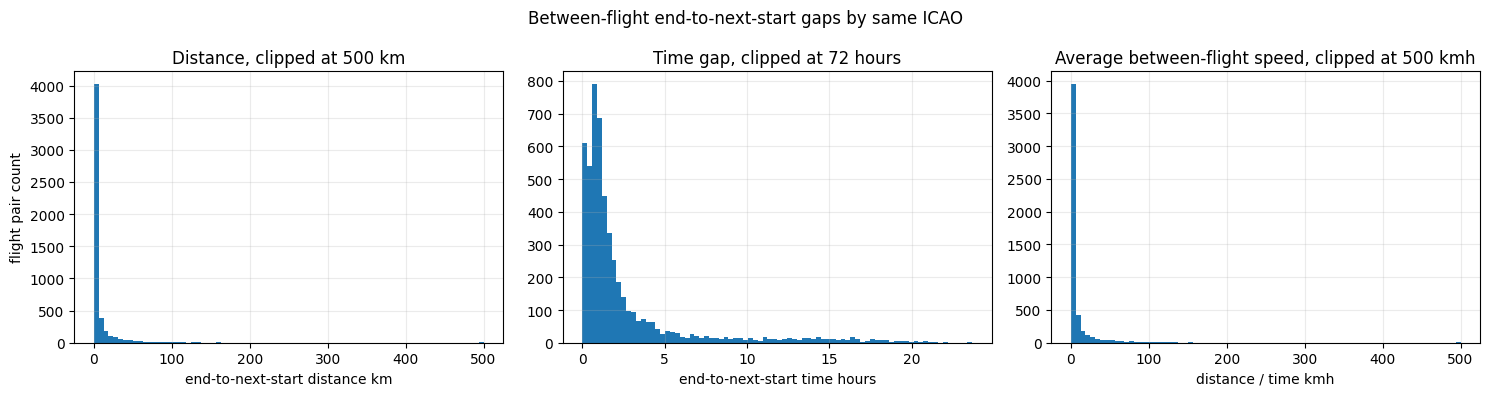

flight_pair_count,icao_count,mean_distance_km,median_distance_km,p90_distance_km,mean_gap_hours,median_gap_hours,p90_gap_hours,mean_distance_per_hour_kmh,median_distance_per_hour_kmh,p90_distance_per_hour_kmh
u32,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64
5177,2544,16.425904,1.537525,22.55849,2.559284,1.165986,6.6669,10.927091,1.470102,24.923923


icao,flight_pair_count,mean_distance_km,mean_gap_hours,mean_distance_per_hour_kmh
str,u32,f64,f64,f64
"""ab4ea9""",1,8332.868171,13.226742,630.001582
"""acfc26""",1,7485.355417,13.721294,545.528372
"""a05483""",1,2709.199227,5.758826,470.442942
"""a3edcf""",1,82.460191,0.239735,343.964323
"""a678cf""",1,1901.307815,5.547221,342.749617
…,…,…,…,…
"""acc9ec""",1,99.414238,0.971172,102.3652
"""ac3d0f""",1,89.787482,0.896894,100.109307
"""ababb9""",4,251.888785,1.587522,98.492232


In [18]:
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import display

max_between_flight_gap_days = 14
distance_clip_km = 500
time_gap_clip_hours = 72
avg_speed_clip_kmh = 500

lat_1 = pl.col("last_lat").radians()
lat_2 = pl.col("next_first_lat").radians()
delta_lat = (pl.col("next_first_lat") - pl.col("last_lat")).radians()
delta_lon = (pl.col("next_first_lon") - pl.col("last_lon")).radians()
haversine_a = (
    (delta_lat / 2).sin() ** 2
    + lat_1.cos() * lat_2.cos() * (delta_lon / 2).sin() ** 2
)
between_flight_distance_km = 6371.0 * 2 * pl.arctan2(
    haversine_a.sqrt(),
    (pl.lit(1.0) - haversine_a).sqrt(),
)

between_flight_gaps = (
    df
    .select([
        "icao",
        "registration",
        "takeoff_time",
        "landing_time",
        "first_lat",
        "first_lon",
        "last_lat",
        "last_lon",
    ])
    .filter(
        pl.col("icao").is_not_null()
        & pl.col("takeoff_time").is_not_null()
        & pl.col("landing_time").is_not_null()
        & (pl.col("landing_time") > pl.col("takeoff_time"))
        & pl.col("first_lat").is_not_null()
        & pl.col("first_lon").is_not_null()
        & pl.col("last_lat").is_not_null()
        & pl.col("last_lon").is_not_null()
    )
    .sort(["icao", "takeoff_time"])
    .with_columns(
        pl.col("takeoff_time").shift(-1).over("icao").alias("next_takeoff_time"),
        pl.col("first_lat").shift(-1).over("icao").alias("next_first_lat"),
        pl.col("first_lon").shift(-1).over("icao").alias("next_first_lon"),
    )
    .filter(pl.col("next_takeoff_time").is_not_null())
    .with_columns(
        (
            (pl.col("next_takeoff_time") - pl.col("landing_time"))
            .dt.total_milliseconds()
            / 1000
            / 60
            / 60
        ).alias("between_flight_gap_hours"),
        between_flight_distance_km.alias("between_flight_distance_km"),
    )
    .filter(
        (pl.col("between_flight_gap_hours") > 0)
        & (pl.col("between_flight_gap_hours") <= max_between_flight_gap_days * 24)
    )
    .with_columns(
        (pl.col("between_flight_distance_km") / pl.col("between_flight_gap_hours"))
        .alias("between_flight_avg_kmh")
    )
)

between_flight_gap_summary = between_flight_gaps.select(
    pl.len().alias("flight_pair_count"),
    pl.col("icao").n_unique().alias("icao_count"),
    pl.col("between_flight_distance_km").mean().alias("mean_distance_km"),
    pl.col("between_flight_distance_km").median().alias("median_distance_km"),
    pl.col("between_flight_distance_km").quantile(0.90).alias("p90_distance_km"),
    pl.col("between_flight_gap_hours").mean().alias("mean_gap_hours"),
    pl.col("between_flight_gap_hours").median().alias("median_gap_hours"),
    pl.col("between_flight_gap_hours").quantile(0.90).alias("p90_gap_hours"),
    pl.col("between_flight_avg_kmh").mean().alias("mean_distance_per_hour_kmh"),
    pl.col("between_flight_avg_kmh").median().alias("median_distance_per_hour_kmh"),
    pl.col("between_flight_avg_kmh").quantile(0.90).alias("p90_distance_per_hour_kmh"),
)

between_flight_gap_by_icao = (
    between_flight_gaps
    .group_by("icao")
    .agg(
        pl.len().alias("flight_pair_count"),
        pl.col("between_flight_distance_km").mean().alias("mean_distance_km"),
        pl.col("between_flight_gap_hours").mean().alias("mean_gap_hours"),
        pl.col("between_flight_avg_kmh").mean().alias("mean_distance_per_hour_kmh"),
    )
    .sort("mean_distance_per_hour_kmh", descending=True)
)

plot_pdf = between_flight_gaps.to_pandas()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(
    plot_pdf["between_flight_distance_km"].clip(upper=distance_clip_km),
    bins=80,
)
axes[0].set_xlabel("end-to-next-start distance km")
axes[0].set_ylabel("flight pair count")
axes[0].set_title(f"Distance, clipped at {distance_clip_km:,} km")
axes[0].grid(alpha=0.25)

axes[1].hist(
    plot_pdf["between_flight_gap_hours"].clip(upper=time_gap_clip_hours),
    bins=80,
)
axes[1].set_xlabel("end-to-next-start time hours")
axes[1].set_title(f"Time gap, clipped at {time_gap_clip_hours:,} hours")
axes[1].grid(alpha=0.25)

axes[2].hist(
    plot_pdf["between_flight_avg_kmh"].clip(upper=avg_speed_clip_kmh),
    bins=80,
)
axes[2].set_xlabel("distance / time kmh")
axes[2].set_title(f"Average between-flight speed, clipped at {avg_speed_clip_kmh:,} kmh")
axes[2].grid(alpha=0.25)

plt.suptitle("Between-flight end-to-next-start gaps by same ICAO")
plt.tight_layout()
plt.show()

display(between_flight_gap_summary)
between_flight_gap_by_icao.head(50)